In [17]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
print("all libaries import sucessfully")

all libaries import sucessfully


In [18]:
df = pd.read_csv("C:/Users/vidya/OneDrive/Documents/googleplaystore.csv")

print(df.head())
print(df.shape)
print(df.columns)

                                                 App        Category  Rating  \
0     Photo Editor & Candy Camera & Grid & ScrapBook  ART_AND_DESIGN     4.1   
1                                Coloring book moana  ART_AND_DESIGN     3.9   
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  ART_AND_DESIGN     4.7   
3                              Sketch - Draw & Paint  ART_AND_DESIGN     4.5   
4              Pixel Draw - Number Art Coloring Book  ART_AND_DESIGN     4.3   

  Reviews  Size     Installs  Type Price Content Rating  \
0     159   19M      10,000+  Free     0       Everyone   
1     967   14M     500,000+  Free     0       Everyone   
2   87510  8.7M   5,000,000+  Free     0       Everyone   
3  215644   25M  50,000,000+  Free     0           Teen   
4     967  2.8M     100,000+  Free     0       Everyone   

                      Genres      Last Updated         Current Ver  \
0               Art & Design   January 7, 2018               1.0.0   
1  Art & Design;Pretend 

In [19]:
df.info()
print(df.describe(include="all"))
print(df.nunique())

<class 'pandas.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  str    
 1   Category        10841 non-null  str    
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  str    
 4   Size            10841 non-null  str    
 5   Installs        10841 non-null  str    
 6   Type            10840 non-null  str    
 7   Price           10841 non-null  str    
 8   Content Rating  10840 non-null  str    
 9   Genres          10841 non-null  str    
 10  Last Updated    10841 non-null  str    
 11  Current Ver     10833 non-null  str    
 12  Android Ver     10838 non-null  str    
dtypes: float64(1), str(12)
memory usage: 1.1 MB
           App Category       Rating Reviews                Size    Installs  \
count    10841    10841  9367.000000   10841               10841       10841   
unique    9660    

In [20]:
df.columns = df.columns.str.strip()

text_columns = df.select_dtypes(
    include="object"
).columns

for col in text_columns:
    df[col] = df[col].str.strip()

C:\Users\vidya\AppData\Local\Temp\ipykernel_21200\2677268334.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df.select_dtypes(


In [21]:
wrong_rows = df[df["Category"] == "1.9"]

print(wrong_rows)

                                           App Category  Rating Reviews  \
10472  Life Made WI-Fi Touchscreen Photo Frame      1.9    19.0    3.0M   

         Size Installs Type     Price Content Rating             Genres  \
10472  1,000+     Free    0  Everyone            NaN  February 11, 2018   

      Last Updated Current Ver Android Ver  
10472       1.0.19  4.0 and up         NaN  


In [22]:
df = df[df["Category"] != "1.9"].copy()

print("Shape after cleaning:", df.shape)

Shape after cleaning: (10840, 13)


In [23]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 483


In [24]:
df = df.drop_duplicates().copy()

print("Shape after cleaning:", df.shape)

print("Remaining duplicates:", df.duplicated().sum())

Shape after cleaning: (10357, 13)
Remaining duplicates: 0


In [25]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})

print(missing_values)

                Missing Count  Missing Percentage
App                         0                0.00
Category                    0                0.00
Rating                   1465               14.15
Reviews                     0                0.00
Size                        0                0.00
Installs                    0                0.00
Type                        1                0.01
Price                       0                0.00
Content Rating              0                0.00
Genres                      0                0.00
Last Updated                0                0.00
Current Ver                 8                0.08
Android Ver                 2                0.02


In [26]:
missing_type = df[df["Type"].isnull()]

print(missing_type)

                            App Category  Rating Reviews                Size  \
9148  Command & Conquer: Rivals   FAMILY     NaN       0  Varies with device   

     Installs Type Price Content Rating    Genres   Last Updated  \
9148        0  NaN     0   Everyone 10+  Strategy  June 28, 2018   

             Current Ver         Android Ver  
9148  Varies with device  Varies with device  


In [27]:
print(df[df["Rating"].isnull()][["App", "Category", "Reviews"]].head(10))

                                     App             Category Reviews
23                Mcqueen Coloring pages       ART_AND_DESIGN      61
113            Wrinkles and rejuvenation               BEAUTY     182
123               Manicure - nail design               BEAUTY     119
126         Skin Care and Natural Beauty               BEAUTY     654
129  Secrets of beauty, youth and health               BEAUTY      77
130   Recipes and tips for losing weight               BEAUTY      35
134        Lady adviser (beauty, health)               BEAUTY      30
163           Anonymous caller detection  BOOKS_AND_REFERENCE     161
180  SH-02J Owner's Manual (Android 8.0)  BOOKS_AND_REFERENCE       2
185       URBANO V 02 instruction manual  BOOKS_AND_REFERENCE     114


In [28]:
df.loc[
    df["Type"].isnull() & (df["Price"] == "0"),
    "Type"
] = "Free"

print("Missing Type:", df["Type"].isnull().sum())

print(df[df["App"] == "Command & Conquer: Rivals"][["App", "Price", "Type"]])

Missing Type: 0
                            App Price  Type
9148  Command & Conquer: Rivals     0  Free


In [29]:
print(df.isnull().sum())

App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
dtype: int64


print("Before Conversion:")
print(df["Reviews"].dtype)

In [30]:
df["Reviews"] = pd.to_numeric(
    df["Reviews"],
    errors="coerce"
)

print("After Conversion:")
print(df["Reviews"].dtype)

After Conversion:
int64


In [31]:
print(df[["App", "Reviews"]].head(10))

                                                 App  Reviews
0     Photo Editor & Candy Camera & Grid & ScrapBook      159
1                                Coloring book moana      967
2  U Launcher Lite – FREE Live Cool Themes, Hide ...    87510
3                              Sketch - Draw & Paint   215644
4              Pixel Draw - Number Art Coloring Book      967
5                         Paper flowers instructions      167
6            Smoke Effect Photo Maker - Smoke Editor      178
7                                   Infinite Painter    36815
8                               Garden Coloring Book    13791
9                      Kids Paint Free - Drawing Fun      121


In [32]:
def convert_size(value):

    value = str(value).strip()

    if value == "Varies with device":
        return np.nan

    try:
        if value.endswith("M"):
            return float(value[:-1])

        elif value.endswith("k"):
            return float(value[:-1]) / 1024

        else:
            return np.nan

    except ValueError:
        return np.nan

In [33]:
df["Size_MB"] = df["Size"].apply(convert_size)

print(df[["App", "Size", "Size_MB"]].head(10))

                                                 App  Size  Size_MB
0     Photo Editor & Candy Camera & Grid & ScrapBook   19M     19.0
1                                Coloring book moana   14M     14.0
2  U Launcher Lite – FREE Live Cool Themes, Hide ...  8.7M      8.7
3                              Sketch - Draw & Paint   25M     25.0
4              Pixel Draw - Number Art Coloring Book  2.8M      2.8
5                         Paper flowers instructions  5.6M      5.6
6            Smoke Effect Photo Maker - Smoke Editor   19M     19.0
7                                   Infinite Painter   29M     29.0
8                               Garden Coloring Book   33M     33.0
9                      Kids Paint Free - Drawing Fun  3.1M      3.1


In [34]:
print(df["Size_MB"].dtype)

float64


In [35]:
print(df["Installs"].head(10))
print(df["Installs"].dtype)

0        10,000+
1       500,000+
2     5,000,000+
3    50,000,000+
4       100,000+
5        50,000+
6        50,000+
7     1,000,000+
8     1,000,000+
9        10,000+
Name: Installs, dtype: str
str


In [37]:
df["Installs"] = pd.to_numeric(
    df["Installs"]
    .astype("string")
    .str.replace(",", "", regex=False)
    .str.replace("+", "", regex=False),
    errors="coerce"
).astype("Int64")

print("Installs conversion completed!")

Installs conversion completed!


In [38]:
print(df[["App", "Installs"]].head(10))

print("Data Type:", df["Installs"].dtype)

                                                 App  Installs
0     Photo Editor & Candy Camera & Grid & ScrapBook     10000
1                                Coloring book moana    500000
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   5000000
3                              Sketch - Draw & Paint  50000000
4              Pixel Draw - Number Art Coloring Book    100000
5                         Paper flowers instructions     50000
6            Smoke Effect Photo Maker - Smoke Editor     50000
7                                   Infinite Painter   1000000
8                               Garden Coloring Book   1000000
9                      Kids Paint Free - Drawing Fun     10000
Data Type: Int64


In [40]:
print(df["Price"].head(10))
print("Data Type:", df["Price"].dtype)

0    0
1    0
2    0
3    0
4    0
5    0
6    0
7    0
8    0
9    0
Name: Price, dtype: str
Data Type: str


In [42]:
df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("$", "", regex=False)
)

df["Price"] = pd.to_numeric(
    df["Price"],
    errors="coerce"
)

print("Price conversion completed!")

Price conversion completed!


In [44]:
print(df[["App", "Price"]].head(10))

print("Data Type:", df["Price"].dtype)

                                                 App  Price
0     Photo Editor & Candy Camera & Grid & ScrapBook    0.0
1                                Coloring book moana    0.0
2  U Launcher Lite – FREE Live Cool Themes, Hide ...    0.0
3                              Sketch - Draw & Paint    0.0
4              Pixel Draw - Number Art Coloring Book    0.0
5                         Paper flowers instructions    0.0
6            Smoke Effect Photo Maker - Smoke Editor    0.0
7                                   Infinite Painter    0.0
8                               Garden Coloring Book    0.0
9                      Kids Paint Free - Drawing Fun    0.0
Data Type: float64


In [46]:
print(df["Last Updated"].head(10))

print("Before Conversion:")
print(df["Last Updated"].dtype)

0       January 7, 2018
1      January 15, 2018
2        August 1, 2018
3          June 8, 2018
4         June 20, 2018
5        March 26, 2017
6        April 26, 2018
7         June 14, 2018
8    September 20, 2017
9          July 3, 2018
Name: Last Updated, dtype: str
Before Conversion:
str


In [48]:
df["Last Updated"] = pd.to_datetime(
    df["Last Updated"],
    format="%B %d, %Y",
    errors="coerce"
)

print("Date conversion completed!")

Date conversion completed!


In [50]:
print(df[["App", "Last Updated"]].head(10))

print("After Conversion:")
print(df["Last Updated"].dtype)

                                                 App Last Updated
0     Photo Editor & Candy Camera & Grid & ScrapBook   2018-01-07
1                                Coloring book moana   2018-01-15
2  U Launcher Lite – FREE Live Cool Themes, Hide ...   2018-08-01
3                              Sketch - Draw & Paint   2018-06-08
4              Pixel Draw - Number Art Coloring Book   2018-06-20
5                         Paper flowers instructions   2017-03-26
6            Smoke Effect Photo Maker - Smoke Editor   2018-04-26
7                                   Infinite Painter   2018-06-14
8                               Garden Coloring Book   2017-09-20
9                      Kids Paint Free - Drawing Fun   2018-07-03
After Conversion:
datetime64[us]


In [52]:
print("Rating Data Type:")
print(df["Rating"].dtype)

print("\nRating Summary:")
print(df["Rating"].describe())

Rating Data Type:
float64

Rating Summary:
count    8892.000000
mean        4.187877
std         0.522377
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64


In [54]:
invalid_ratings = df[
    (df["Rating"] < 1) |
    (df["Rating"] > 5)
]

print("Invalid Ratings:")
print(invalid_ratings[["App", "Rating"]])

print("Total Invalid Ratings:", len(invalid_ratings))

Invalid Ratings:
Empty DataFrame
Columns: [App, Rating]
Index: []
Total Invalid Ratings: 0


In [56]:
df.loc[
    (df["Rating"] < 1) |
    (df["Rating"] > 5),
    "Rating"
] = np.nan

print("Rating validation completed!")

Rating validation completed!


In [58]:
print("Minimum Rating:", df["Rating"].min())
print("Maximum Rating:", df["Rating"].max())

print("Missing Ratings:", df["Rating"].isnull().sum())

Minimum Rating: 1.0
Maximum Rating: 5.0
Missing Ratings: 1465


In [60]:
print("Category Values:")
print(df["Category"].value_counts().head(20))

print("\nType Values:")
print(df["Type"].value_counts())

print("\nGenres Values:")
print(df["Genres"].value_counts().head(20))

Category Values:
Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
Name: count, dtype: int64

Type Values:
Type
Free    9592
Paid     765
Name: count, dtype: int64

Genres Values:
Genres
Tools                842
Entertainment        588
Education            527
Business             427
Medical              408
Productivity         407
Personalization      388
Lifestyle            372
Communication        366
Sports               364
Finance              360
Action             

In [62]:
print("Category:")
print(df["Category"].value_counts().head(10))

print("\nType:")
print(df["Type"].value_counts())

print("\nGenres:")
print(df["Genres"].head(10))

Category:
Category
FAMILY             1943
GAME               1121
TOOLS               843
BUSINESS            427
MEDICAL             408
PRODUCTIVITY        407
PERSONALIZATION     388
LIFESTYLE           373
COMMUNICATION       366
FINANCE             360
Name: count, dtype: int64

Type:
Type
Free    9592
Paid     765
Name: count, dtype: int64

Genres:
0                 Art & Design
1    Art & Design;Pretend Play
2                 Art & Design
3                 Art & Design
4      Art & Design;Creativity
5                 Art & Design
6                 Art & Design
7                 Art & Design
8                 Art & Design
9      Art & Design;Creativity
Name: Genres, dtype: str


In [66]:
print("Final Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Final Missing Values:
App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1526
dtype: int64

Total Missing Values:
3001


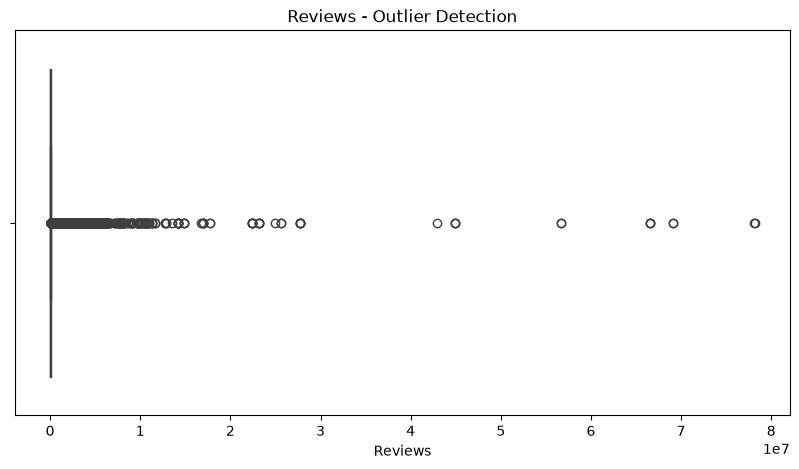

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["Reviews"])

plt.title("Reviews - Outlier Detection")
plt.show()

In [67]:
Q1 = df["Reviews"].quantile(0.25)
Q3 = df["Reviews"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Reviews"] < lower_limit) |
    (df["Reviews"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Outliers:", len(outliers))

Lower Limit: -69544.0
Upper Limit: 115992.0
Total Outliers: 1870


In [69]:
Q1 = df["Installs"].quantile(0.25)
Q3 = df["Installs"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Installs"] < lower_limit) |
    (df["Installs"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Installs Outliers:", len(outliers))

Lower Limit: -1497500.0
Upper Limit: 2498500.0
Total Installs Outliers: 2566


In [71]:
Q1 = df["Price"].quantile(0.25)
Q3 = df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

price_outliers = df[
    (df["Price"] < lower_limit) |
    (df["Price"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Price Outliers:", len(price_outliers))

Lower Limit: 0.0
Upper Limit: 0.0
Total Price Outliers: 765


In [73]:
Q1 = df["Size_MB"].quantile(0.25)
Q3 = df["Size_MB"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

size_outliers = df[
    (df["Size_MB"] < lower_limit) |
    (df["Size_MB"] > upper_limit)
]

print("Lower Limit:", lower_limit)
print("Upper Limit:", upper_limit)
print("Total Size Outliers:", len(size_outliers))

Lower Limit: -31.750000000000004
Upper Limit: 65.45
Total Size Outliers: 582


In [75]:
print("Missing Values:")
print(df.isnull().sum())

print("\nTotal Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
App                  0
Category             0
Rating            1465
Reviews              0
Size                 0
Installs             0
Type                 0
Price                0
Content Rating       0
Genres               0
Last Updated         0
Current Ver          8
Android Ver          2
Size_MB           1526
dtype: int64

Total Missing Values:
3001


In [77]:
print("Final Dataset Shape:", df.shape)

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nData Types:")
print(df.dtypes)

print("\nInvalid Ratings:")
print(len(df[(df["Rating"] < 1) | (df["Rating"] > 5)]))

print("\nNegative Prices:")
print(len(df[df["Price"] < 0]))

print("\nNegative Installs:")
print(len(df[df["Installs"] < 0]))

Final Dataset Shape: (10357, 14)

Duplicate Rows: 0

Data Types:
App                          str
Category                     str
Rating                   float64
Reviews                    int64
Size                         str
Installs                   Int64
Type                         str
Price                    float64
Content Rating               str
Genres                       str
Last Updated      datetime64[us]
Current Ver                  str
Android Ver                  str
Size_MB                  float64
dtype: object

Invalid Ratings:
0

Negative Prices:
0

Negative Installs:
0


In [79]:
df.to_csv("googleplaystore_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [81]:
category_count = df["Category"].value_counts()

print(category_count)

Category
FAMILY                 1943
GAME                   1121
TOOLS                   843
BUSINESS                427
MEDICAL                 408
PRODUCTIVITY            407
PERSONALIZATION         388
LIFESTYLE               373
COMMUNICATION           366
FINANCE                 360
SPORTS                  351
PHOTOGRAPHY             322
HEALTH_AND_FITNESS      306
SOCIAL                  280
NEWS_AND_MAGAZINES      264
TRAVEL_AND_LOCAL        237
BOOKS_AND_REFERENCE     230
SHOPPING                224
DATING                  196
VIDEO_PLAYERS           175
MAPS_AND_NAVIGATION     137
EDUCATION               130
FOOD_AND_DRINK          124
ENTERTAINMENT           111
AUTO_AND_VEHICLES        85
LIBRARIES_AND_DEMO       85
WEATHER                  82
HOUSE_AND_HOME           80
ART_AND_DESIGN           65
EVENTS                   64
COMICS                   60
PARENTING                60
BEAUTY                   53
Name: count, dtype: int64


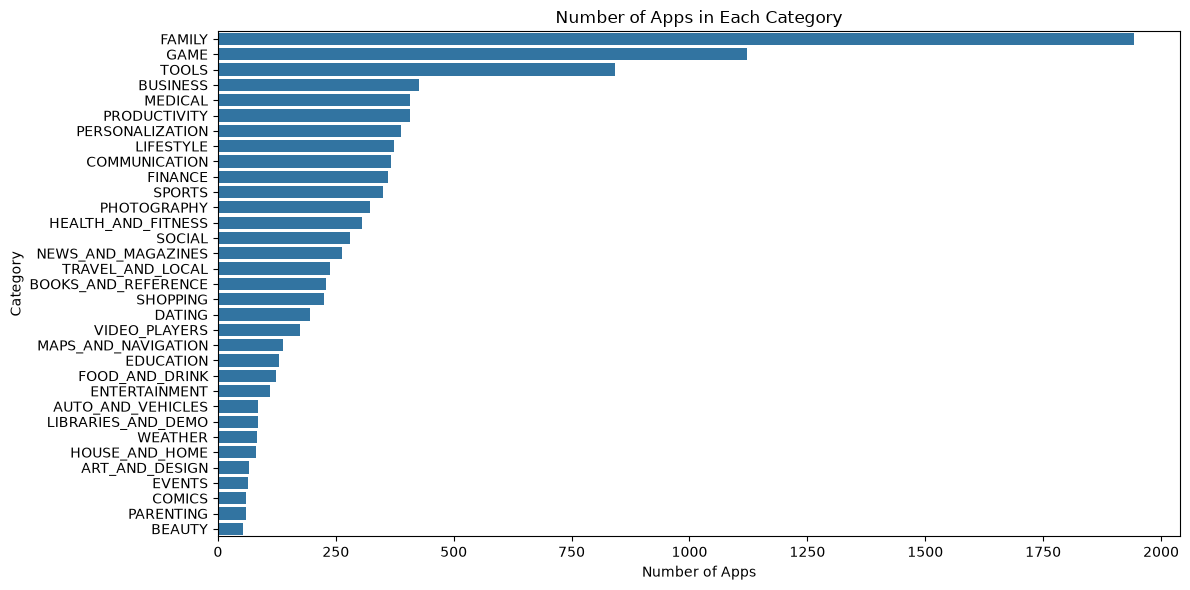

In [82]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    y="Category",
    order=df["Category"].value_counts().index
)

plt.title("Number of Apps in Each Category")
plt.xlabel("Number of Apps")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Type
Free    9592
Paid     765
Name: count, dtype: int64


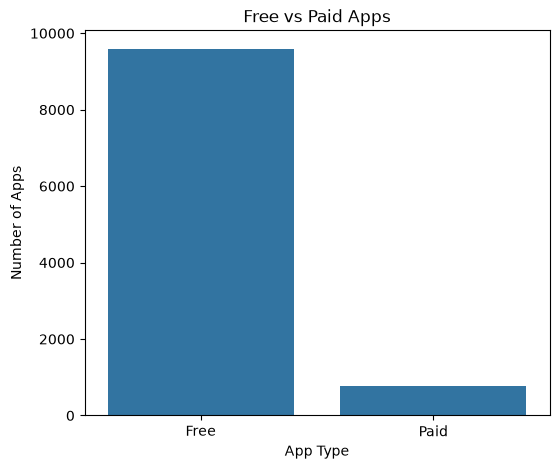

In [84]:
type_count = df["Type"].value_counts()

print(type_count)

plt.figure(figsize=(6, 5))
sns.countplot(data=df, x="Type")

plt.title("Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Number of Apps")
plt.show()

Average App Rating: 4.187876743139901

Highest Rating: 5.0
Lowest Rating: 1.0


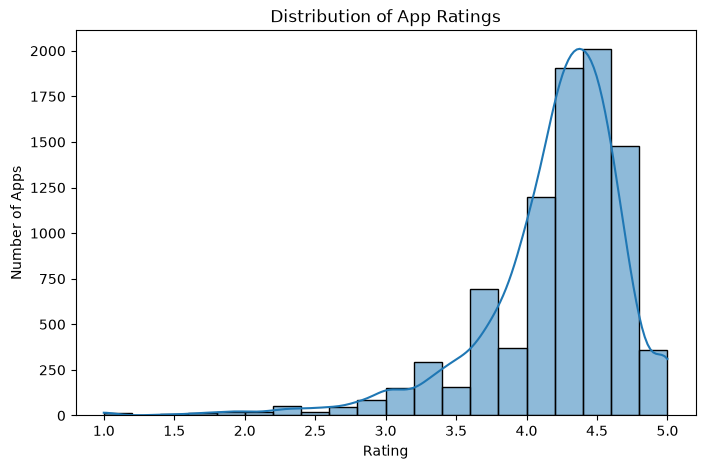

In [86]:
print("Average App Rating:", df["Rating"].mean())
print("\nHighest Rating:", df["Rating"].max())
print("Lowest Rating:", df["Rating"].min())

plt.figure(figsize=(8, 5))

sns.histplot(df["Rating"].dropna(), bins=20, kde=True)

plt.title("Distribution of App Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Apps")

plt.show()

                            App            Category    Installs
3454               Google Drive        PRODUCTIVITY  1000000000
865           Google Play Games       ENTERTAINMENT  1000000000
3523               Google Drive        PRODUCTIVITY  1000000000
2544                   Facebook              SOCIAL  1000000000
2545                  Instagram              SOCIAL  1000000000
464                    Hangouts       COMMUNICATION  1000000000
3223  Maps - Navigate & Explore    TRAVEL_AND_LOCAL  1000000000
3816                Google News  NEWS_AND_MAGAZINES  1000000000
4170               Google Drive        PRODUCTIVITY  1000000000
3896             Subway Surfers                GAME  1000000000


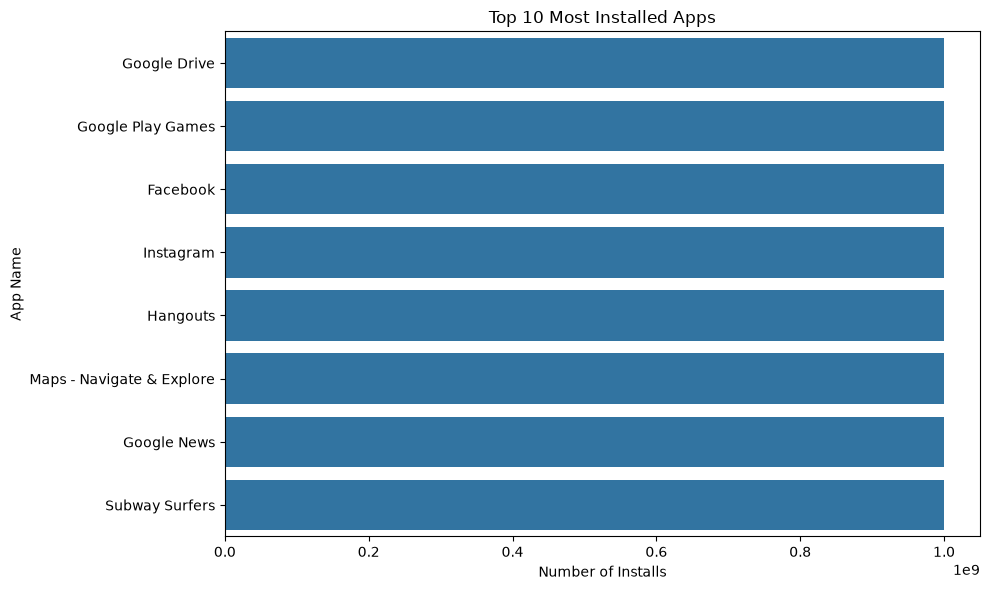

In [87]:
top_10_apps = df.sort_values(
    by="Installs",
    ascending=False
).head(10)

print(top_10_apps[["App", "Category", "Installs"]])

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_10_apps,
    x="Installs",
    y="App"
)

plt.title("Top 10 Most Installed Apps")
plt.xlabel("Number of Installs")
plt.ylabel("App Name")
plt.tight_layout()
plt.show()

Category
EVENTS                 4.435556
EDUCATION              4.375969
ART_AND_DESIGN         4.358065
BOOKS_AND_REFERENCE    4.347458
PERSONALIZATION        4.333871
PARENTING              4.300000
GAME                   4.281285
BEAUTY                 4.278571
HEALTH_AND_FITNESS     4.261450
SOCIAL                 4.254918
SHOPPING               4.251485
WEATHER                4.244000
SPORTS                 4.225175
PRODUCTIVITY           4.201796
FAMILY                 4.191153
AUTO_AND_VEHICLES      4.190411
PHOTOGRAPHY            4.182895
MEDICAL                4.182450
LIBRARIES_AND_DEMO     4.178462
HOUSE_AND_HOME         4.164706
FOOD_AND_DRINK         4.164151
COMICS                 4.155172
COMMUNICATION          4.151466
ENTERTAINMENT          4.136036
NEWS_AND_MAGAZINES     4.128505
FINANCE                4.127445
BUSINESS               4.102593
LIFESTYLE              4.096066
TRAVEL_AND_LOCAL       4.094146
VIDEO_PLAYERS          4.063750
MAPS_AND_NAVIGATION    4.051613

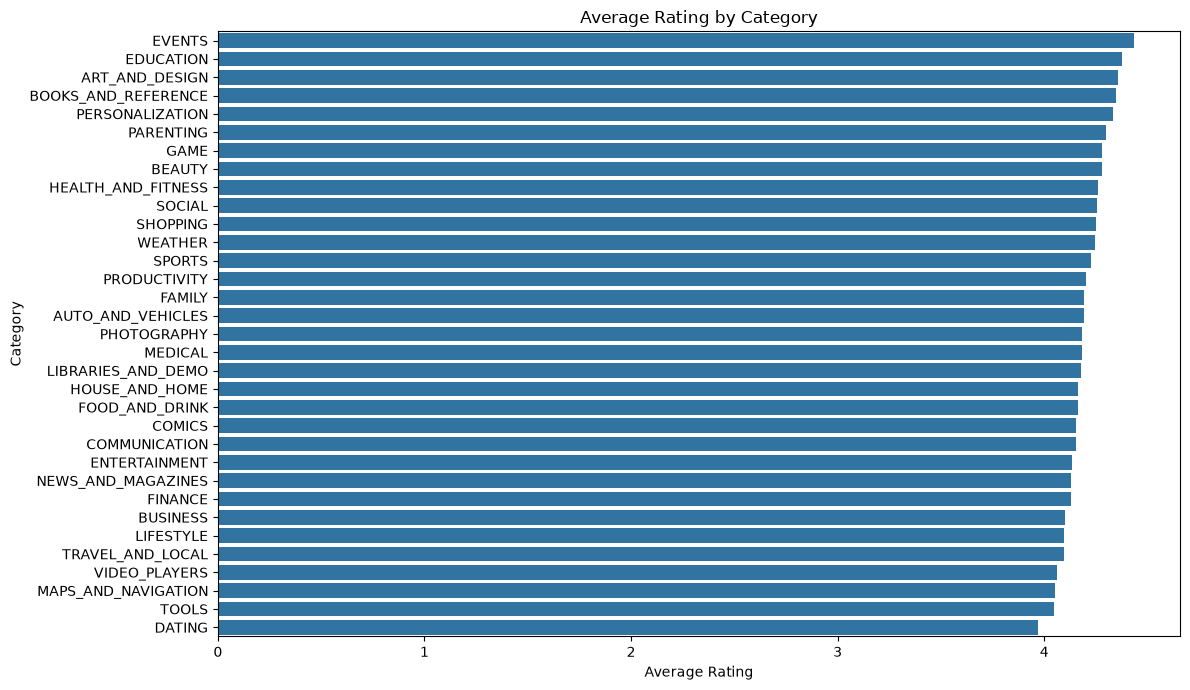

In [88]:
category_rating = df.groupby("Category")["Rating"].mean().sort_values(ascending=False)

print(category_rating)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_rating.values,
    y=category_rating.index
)

plt.title("Average Rating by Category")
plt.xlabel("Average Rating")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Type
Free    4.182425
Paid    4.261501
Name: Rating, dtype: float64


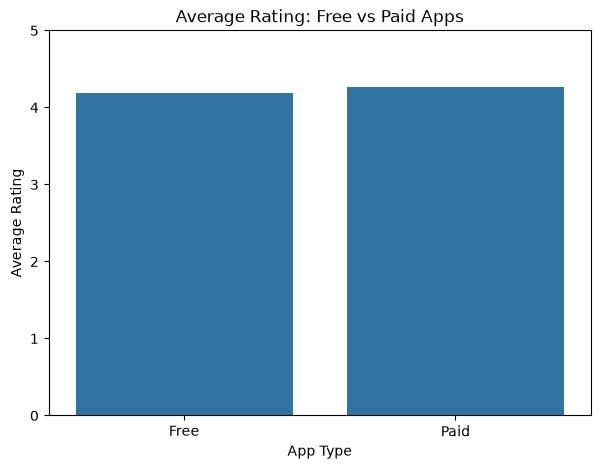

In [89]:
type_rating = df.groupby("Type")["Rating"].mean()

print(type_rating)

plt.figure(figsize=(7, 5))

sns.barplot(
    x=type_rating.index,
    y=type_rating.values
)

plt.title("Average Rating: Free vs Paid Apps")
plt.xlabel("App Type")
plt.ylabel("Average Rating")
plt.ylim(0, 5)

plt.show()

In [91]:
df.to_csv("googleplaystore_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


Category
COMMUNICATION          65989825.822404
SOCIAL                 44692385.364286
VIDEO_PLAYERS          35554301.257143
PRODUCTIVITY           30621846.115479
PHOTOGRAPHY            30190210.108696
GAME                    28139183.24264
TRAVEL_AND_LOCAL       26843405.679325
ENTERTAINMENT          22123063.063063
NEWS_AND_MAGAZINES     20428855.151515
TOOLS                  13585731.809015
SHOPPING                11488164.21875
BOOKS_AND_REFERENCE     8332476.417391
PERSONALIZATION         5346636.036082
MAPS_AND_NAVIGATION     5286729.124088
WEATHER                 5196347.804878
FAMILY                  5168138.190942
HEALTH_AND_FITNESS      4447785.986928
SPORTS                  4354913.099715
EDUCATION               4107323.076923
FINANCE                 2139857.594444
FOOD_AND_DRINK          2079828.637097
BUSINESS                2022634.344262
ART_AND_DESIGN          1912893.846154
HOUSE_AND_HOME            1565155.7625
LIFESTYLE               1433843.268097
DATING          

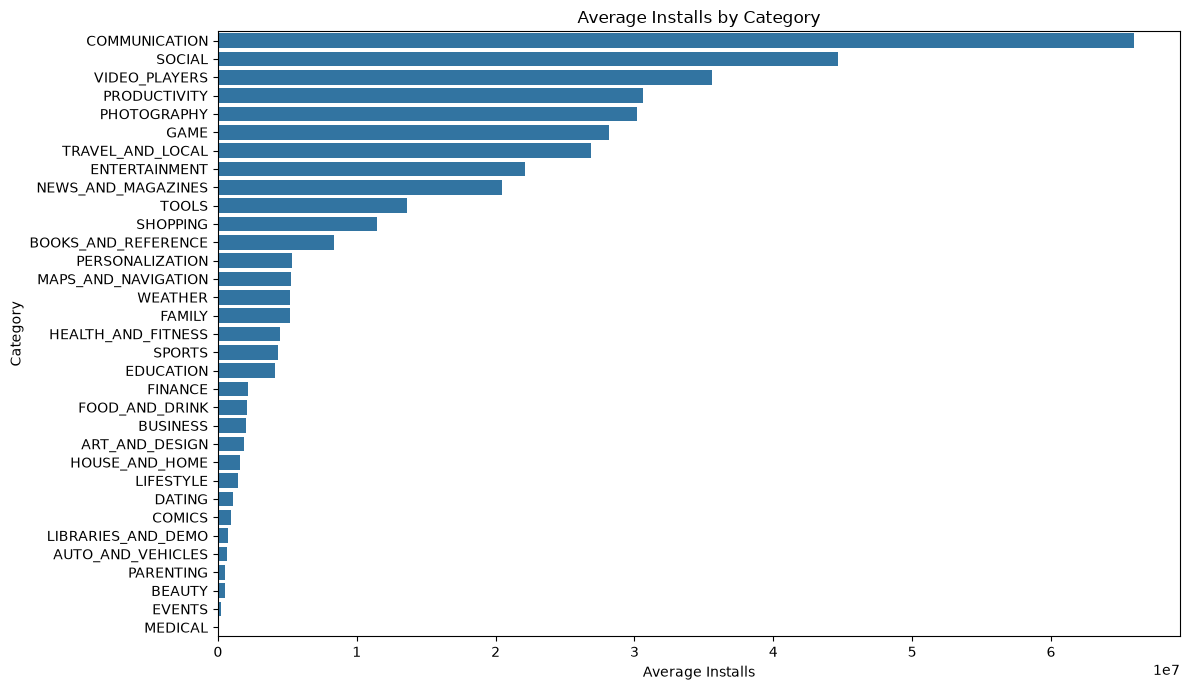

In [93]:
category_installs = df.groupby("Category")["Installs"].mean().sort_values(ascending=False)

print(category_installs)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=category_installs.values,
    y=category_installs.index
)

plt.title("Average Installs by Category")
plt.xlabel("Average Installs")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

            Rating   Reviews  Installs     Price   Size_MB
Rating    1.000000  0.068732  0.050886 -0.022355  0.081969
Reviews   0.068732  1.000000  0.634997 -0.009417  0.237891
Installs  0.050886  0.634997  1.000000 -0.011147  0.168872
Price    -0.022355 -0.009417 -0.011147  1.000000 -0.023769
Size_MB   0.081969  0.237891  0.168872 -0.023769  1.000000


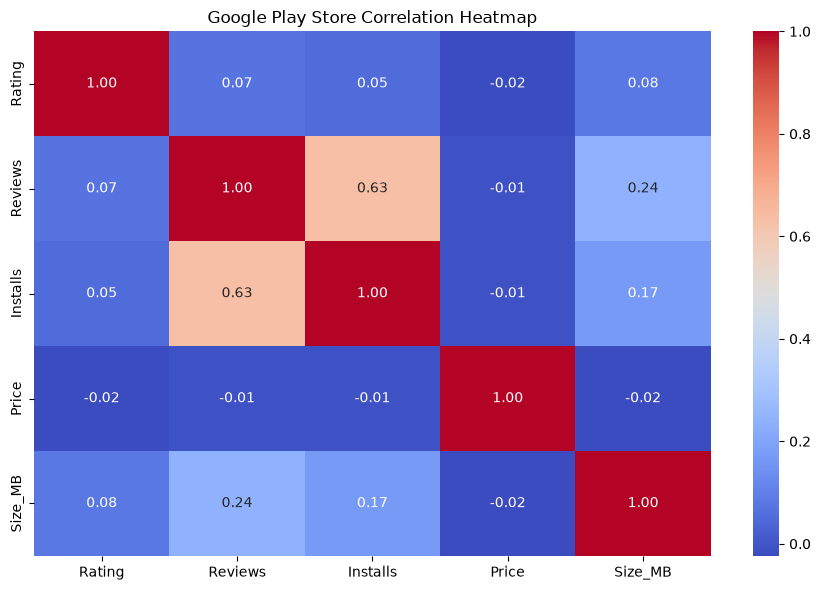

In [99]:
numeric_data = df[
    ["Rating", "Reviews", "Installs", "Price", "Size_MB"]
].copy()

correlation = numeric_data.corr()

print(correlation)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Google Play Store Correlation Heatmap")
plt.tight_layout()
plt.show()

In [97]:
print("GOOGLE PLAY STORE - BUSINESS INSIGHTS")

print("\n1. Total Apps:", len(df))

print("\n2. Average Rating:", round(df["Rating"].mean(), 2))

print("\n3. Most Common Category:")
print(df["Category"].value_counts().idxmax())

print("\n4. Most Installed App:")
print(df.loc[df["Installs"].idxmax(), "App"])

print("\n5. Most Reviewed App:")
print(df.loc[df["Reviews"].idxmax(), "App"])

print("\n6. Free Apps:", (df["Type"] == "Free").sum())

print("\n7. Paid Apps:", (df["Type"] == "Paid").sum())

print("\n8. Average App Size (MB):", round(df["Size_MB"].mean(), 2))

GOOGLE PLAY STORE - BUSINESS INSIGHTS

1. Total Apps: 10357

2. Average Rating: 4.19

3. Most Common Category:
FAMILY

4. Most Installed App:
Google Play Books

5. Most Reviewed App:
Facebook

6. Free Apps: 9592

7. Paid Apps: 765

8. Average App Size (MB): 21.29


In [102]:
insights = {
    "Metric": [
        "Total Apps",
        "Average Rating",
        "Most Common Category",
        "Most Installed App",
        "Most Reviewed App",
        "Free Apps",
        "Paid Apps",
        "Average App Size (MB)"
    ],
    "Value": [
        len(df),
        round(df["Rating"].mean(), 2),
        df["Category"].value_counts().idxmax(),
        df.loc[df["Installs"].idxmax(), "App"],
        df.loc[df["Reviews"].idxmax(), "App"],
        (df["Type"] == "Free").sum(),
        (df["Type"] == "Paid").sum(),
        round(df["Size_MB"].mean(), 2)
    ]
}

insights_df = pd.DataFrame(insights)

insights_df.to_csv("googleplaystore_business_insights.csv", index=False)

print(insights_df)
print("\nBusiness insights saved successfully!")

                  Metric              Value
0             Total Apps              10357
1         Average Rating               4.19
2   Most Common Category             FAMILY
3     Most Installed App  Google Play Books
4      Most Reviewed App           Facebook
5              Free Apps               9592
6              Paid Apps                765
7  Average App Size (MB)              21.29

Business insights saved successfully!


In [104]:
# Descriptive Statistical Analysis

print("DESCRIPTIVE STATISTICAL ANALYSIS")

print("\nMean:")
print(df[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].mean())

print("\nMedian:")
print(df[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].median())

print("\nMode:")
print(df[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].mode().iloc[0])

print("\nStatistical Summary:")
print(df[["Rating", "Reviews", "Installs", "Price", "Size_MB"]].describe())

DESCRIPTIVE STATISTICAL ANALYSIS

Mean:
Rating             4.187877
Reviews       405904.610602
Installs    14157759.440668
Price                1.0308
Size_MB           21.287413
dtype: Float64

Median:
Rating           4.3
Reviews       1680.0
Installs    100000.0
Price            0.0
Size_MB         13.0
dtype: Float64

Mode:
Rating            4.4
Reviews           0.0
Installs    1000000.0
Price             0.0
Size_MB          11.0
Name: 0, dtype: Float64

Statistical Summary:
            Rating       Reviews         Installs         Price      Size_MB
count  8892.000000  1.035700e+04          10357.0  10357.000000  8831.000000
mean      4.187877  4.059046e+05  14157759.440668      1.030800    21.287413
std       0.522377  2.696778e+06  80239553.869019     16.278625    22.540591
min       1.000000  0.000000e+00              0.0      0.000000     0.008301
25%       4.000000  3.200000e+01           1000.0      0.000000     4.700000
50%       4.300000  1.680000e+03         100000.0  

In [105]:
print("PROJECT RECOMMENDATIONS")

print("1. Developers should focus on improving app ratings.")
print("2. Developers should provide regular app updates.")
print("3. Popular app categories can be considered for new app development.")
print("4. Apps should be optimized for better user experience.")
print("5. Developers should analyze user reviews to improve app quality.")

PROJECT RECOMMENDATIONS
1. Developers should focus on improving app ratings.
2. Developers should provide regular app updates.
3. Popular app categories can be considered for new app development.
4. Apps should be optimized for better user experience.
5. Developers should analyze user reviews to improve app quality.
